In [11]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
import corner

import sys
sys.path.append('/home/hedi/HSCNG/peaks')

name_fields = ['XMM', 'VVDS', 'GAMA09H', 'GAMA15H', 'WIDE12H', 'HECTOMAP']
number_patches = [8, 25, 23, 7, 26, 13]
tomo_bin = [1, 2, 3, 4]
# _GALAXY_COUNTS_TOMOBIN_ = {}

# for field, Npatch in zip(name_fields, number_patches):
#     dats = [
#         fits.getdata(f'~/HSCNG/data/real/hscy3_shape_chopped_{field}_{i}.fits')
#         for i in range(Npatch)
#     ]
#     dat = np.concatenate(dats)
#     _numbers = []
#     for tomo_bin in [1, 2, 3, 4]:
#         _numbers.append((dat['hsc_y3_zbin'] == tomo_bin).sum())
#     _GALAXY_COUNTS_TOMOBIN_[field] = _numbers
from MCMC_peak_g import *

In [16]:
tomo = 4
signals = []
for field in name_fields:
    dat = np.load(f'/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/stats_fiducial/peaks/Peaks_z{tomo}_{field}.npy')
    signal_mean = np.mean(dat, axis=0)
    signals.append(signal_mean)
peak_fid = np.sum(signals, axis=0)

In [17]:
tomo = 4
signals_cosmo_varied = []
for cosmology_id in range(50):
    signals = []
    for field in name_fields:
        dat = np.load(f'/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/stats_cosmo_varied/peaks/model{cosmology_id}_Peaks_z{tomo}_{field}.npy')
        signal_mean = np.mean(dat, axis=0)      # average over 50 realizations
        signals.append(signal_mean)

    signals_cosmo_varied.append(np.sum(signals, axis=0))


In [18]:
edge = np.linspace(-4, 4, 20)
xx = 0.5 * (edge[1:] + edge[:-1])

# slice_ell = (xx >= 300) & (xx <= 1500)          # apply a cut here.
# load mock results

peak_results = []
for tomo in [1, 2, 3, 4]:
    signal_cosmo_varied = []
    for cosmo_id in range(50):
        if cosmo_id == cosmology_id:
            continue
        signals = []
        for field in name_fields:
            dat = np.load(f'/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/stats_cosmo_varied/peaks/model{cosmo_id}_Peaks_z{tomo}_{field}.npy')
            peak_mean = np.mean(dat, axis=0)      # average over 50 realizations
            signals.append(peak_mean)

        signal_cosmo_varied.append(np.sum(signals, axis=0))     # sum over all fields
    peak_results.append(np.array(signal_cosmo_varied))

slice = peak_results[0][0] > 15

In [29]:
x_edge = np.linspace(-4, 4, 20)
xx = 0.5 * (x_edge[1:] + x_edge[:-1])

In [38]:
signals_cosmo_varied[0] > 15

array([False, False, False, False, False, False, False, False, False,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True])

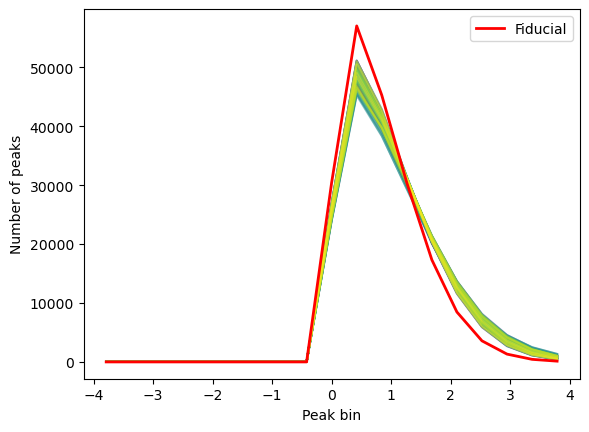

In [31]:
cmap = plt.cm.viridis
for i in range(50):
    plt.plot(xx, signals_cosmo_varied[i], alpha=0.5, color=cmap(i / 49))

plt.plot(xx, peak_fid, color='red', linewidth=2, label='Fiducial')
plt.xlabel('Peak bin')
plt.ylabel('Number of peaks')
plt.legend()
plt.show()

In [1]:
import os
os.chdir('/home/hedi/HSCNG/peaks')

In [2]:
from MCMC_peak_g import *

In [3]:
res_dict = prepare_data(cosmology_id=0, realization_id=10)

In [5]:
x_plot = res_dict['x']
signal_i = res_dict['signal']
covs_i = res_dict['covs']
gprs = res_dict['gprs']

In [7]:
res_dict['true_value']

{'Om': np.float64(0.31315),
 'S8': np.float64(0.83954),
 'H0': np.float64(0.6737)}

In [8]:
Om = res_dict['true_value']['Om']
S8 = np.linspace(0.6, 0.9, 50)
H0 = res_dict['true_value']['H0']


Om = Om * np.ones_like(S8)
H0 = H0 * np.ones_like(S8)

In [9]:
x_t = np.c_[Om, S8, H0]
ys = gprs[0].predict(x_t)

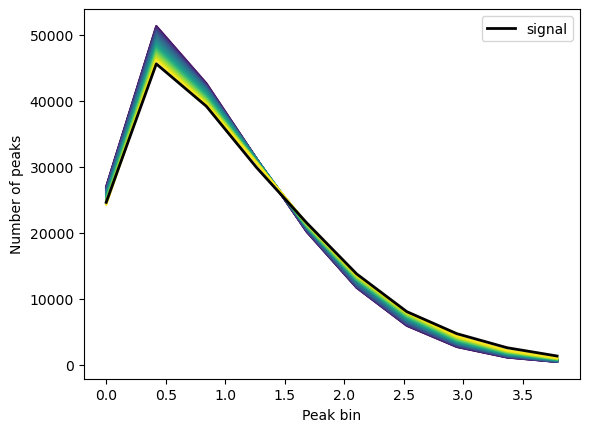

In [13]:
cmap = plt.cm.viridis

tomo = 4

x_t = np.c_[Om, S8, H0]
ys = gprs[tomo-1].predict(x_t)

for i in range(ys.shape[0]):
    plt.plot(x_plot, ys[i], color=cmap(i / max(1, ys.shape[0] - 1)), alpha=0.7)

plt.plot(x_plot, signal_i[tomo-1], color='black', linewidth=2, label='signal')

plt.xlabel('Peak bin')
plt.ylabel('Number of peaks')
plt.legend()
plt.show()

In [12]:
cosmology_id = 37
S_8 = []
for i in [48,  4,  0, 40,  2, 43, 47, 21,  9, 19]:
    backend = emcee.backends.HDFBackend(f"/home/hedi/data/backend_pow_g/mcmc_power_results_{cosmology_id}_{i}.h5")
    try:
        chain = backend.get_chain(flat=True, discard=100)
        # if len(chain) < 2495000:
            # print(f"Chain {i} has length {len(chain)}")
            # continue
    except:
        continue
    S_8.append(chain[:, 1])

In [13]:
data = prepare_data(cosmology_id, 0)
true_value = data['true_value']

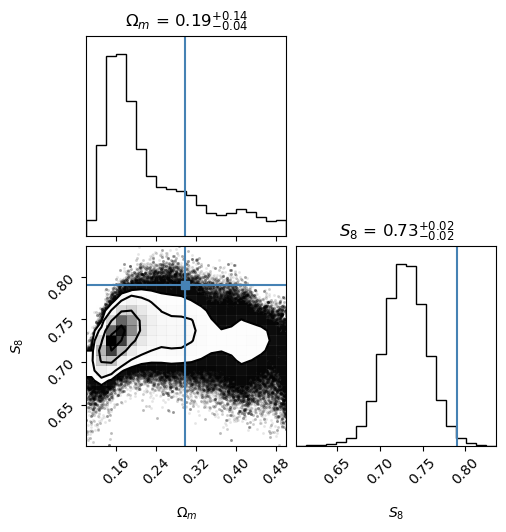

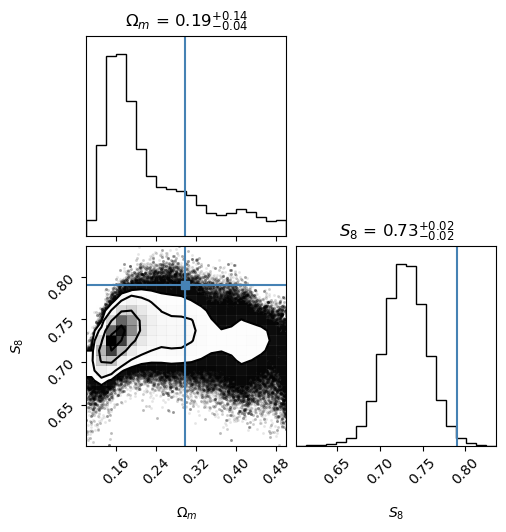

In [14]:
corner.corner(chain, truths=[true_value['Om'], true_value['S8']], labels=[r"$\Omega_m$", r"$S_8$"], show_titles=True, title_kwargs={"fontsize": 12})

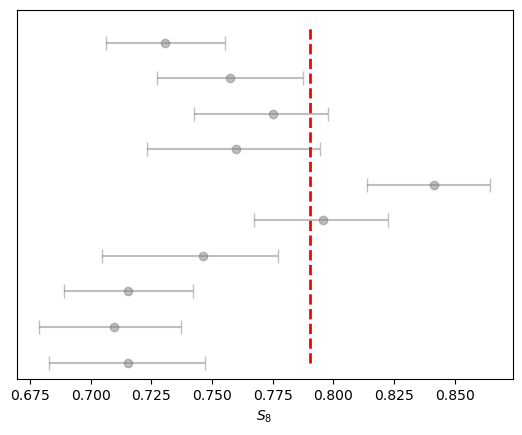

In [15]:
res = np.quantile(S_8, [0.16, 0.5, 0.84], axis=1)

# res_mean = np.quantile(S_mean, [0.16, 0.5, 0.84], axis=0)
plt.errorbar(res[1], np.arange(res.shape[1]), xerr=[res[1]-res[0], res[2]-res[1]], fmt='o', capsize=5, color='grey', alpha=0.5)
# plt.errorbar(res_mean[1], [-1], xerr=[[res_mean[1]-res_mean[0]], [res_mean[2]-res_mean[1]]], fmt='o', capsize=5, color='red', label='mean of realizations')
plt.yticks([])
plt.xlabel(r'$S_8$')
plt.vlines(true_value['S8'], ymin=0, ymax=plt.ylim()[1], color='red', linestyle='--', label='True Value', linewidth=2)

In [2]:
cosmo_pars = np.loadtxt('/home/hedi/HSCNG/data/cosmo_params.txt', skiprows=1)
cosmo_Om = cosmo_pars[:,1]
cosmo_S8 = cosmo_pars[:,3]
cosmo_H0 = cosmo_pars[:,4]
rms = []
mean_diff = []
sampled_realizations = [48,  4,  0, 40,  2, 43, 47, 21,  9, 19]

for cosmology_id in range(50):
    S_8 = []
    for i in sampled_realizations:
        backend = emcee.backends.HDFBackend(f"/home/hedi/data/backend_peak_g/model{cosmology_id:02d}/mcmc_peak_results_{cosmology_id}_{i}.h5")
        try:
            chain = backend.get_chain(flat=True, discard=100)
        except:
            continue
        S_8.append(chain[:, 1])
    res = np.quantile(S_8, [0.16, 0.5, 0.84], axis=1)

    # # catch convergence warnings during GPR optimization
    # import warnings
    # from sklearn.exceptions import ConvergenceWarning
    # with warnings.catch_warnings(record=True) as caught:
    #     warnings.simplefilter("always", ConvergenceWarning)
    #     data = prepare_data(cosmology_id, sampled_realizations[0])
    # convergence_failed = any(
    #     issubclass(w.category, ConvergenceWarning)
    #     for w in caught
    # )

    # # print(f"Cosmology ID: {cosmology_id}")
    # # for i in range(4):
    # #     print(data['gprs'][i].kernel_)
    # if convergence_failed:
    #     print("GPR optimization did not converge in {}".format(cosmology_id))
    # # print()
    # # end of catch

    # true_value = data['true_value']
    mean_diff.append(np.average((res[1] - cosmo_S8[cosmology_id])/((res[2] - res[0]) / 2)))
    rms.append(np.sqrt(np.average(((res[1] - cosmo_S8[cosmology_id]) / ((res[2] - res[0]) / 2))**2)))


In [3]:
rms = np.array(rms)
mean_diff = np.array(mean_diff)

In [30]:
cosmology_id = 3
chains = []
for i in sampled_realizations:
    backend = emcee.backends.HDFBackend(f"/home/hedi/data/backend_peak_g/model{cosmology_id:02d}/mcmc_peak_results_{cosmology_id}_{i}.h5")
    try:
        chain = backend.get_chain(flat=True, discard=100)
    except:
        continue
    chains.append(chain)

In [34]:
cosmo_Om[cosmology_id], cosmo_S8[cosmology_id]

(np.float64(0.10721), np.float64(0.73513))

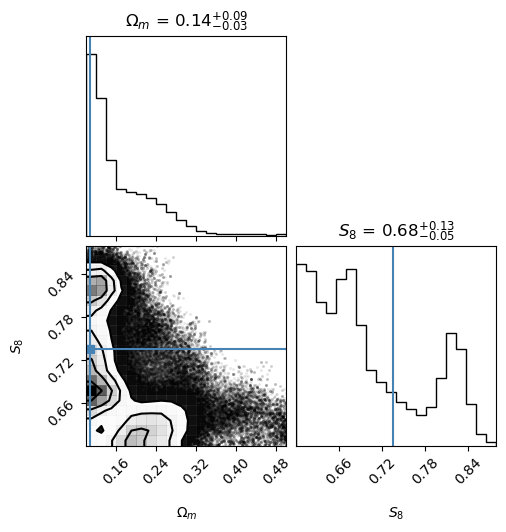

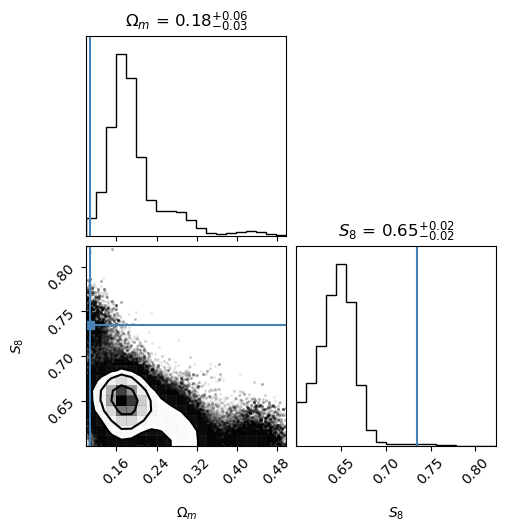

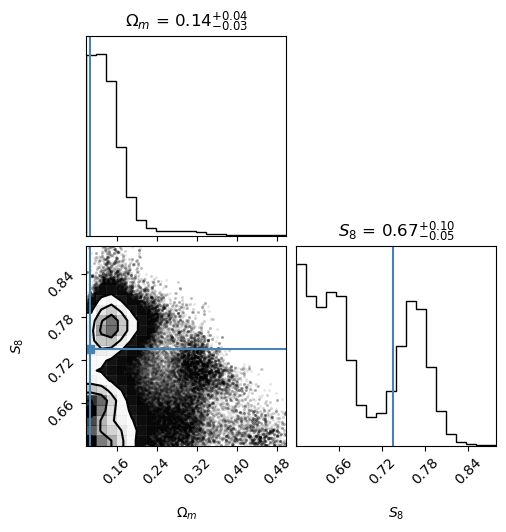

In [33]:
corner.corner(chains[0], truths=[cosmo_Om[cosmology_id], cosmo_S8[cosmology_id]], labels=[r"$\Omega_m$", r"$S_8$"], show_titles=True, title_kwargs={"fontsize": 12}).show()
corner.corner(chains[1], truths=[cosmo_Om[cosmology_id], cosmo_S8[cosmology_id]], labels=[r"$\Omega_m$", r"$S_8$"], show_titles=True, title_kwargs={"fontsize": 12}).show()
corner.corner(chains[2], truths=[cosmo_Om[cosmology_id], cosmo_S8[cosmology_id]], labels=[r"$\Omega_m$", r"$S_8$"], show_titles=True, title_kwargs={"fontsize": 12}).show()

In [28]:
np.where(np.array(rms) > 3)

(array([3]),)

In [46]:
outof_range = np.where(
    (cosmo_S8 < 0.6) | (cosmo_S8 > 0.88) | (cosmo_Om < 0.1) | (cosmo_Om > 0.5)
)[0]

In [4]:
valid = (cosmo_S8 > 0.6) & (cosmo_S8 < 0.88) & (cosmo_Om > 0.1) & (cosmo_Om < 0.5)

Text(0.5, 1.0, 'constrained S8 vs real S8, averaged over 10 realizations')

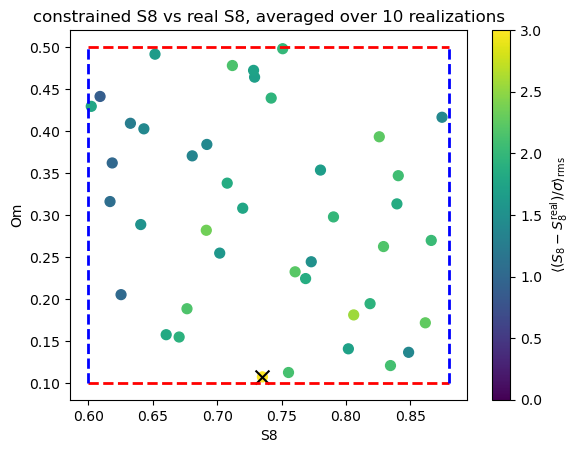

In [10]:
plt.scatter(cosmo_S8[valid], cosmo_Om[valid], c=rms[valid], cmap='viridis', s=50, vmax=3, vmin=0)
plt.colorbar(label=r'$\langle(S_8 - S_8^{\rm real}) / \sigma\rangle_{\rm rms}$')

bad_rms = rms > 3
plt.scatter(cosmo_S8[bad_rms], cosmo_Om[bad_rms], c='black', s=100, marker='x', label='bad behavior')

Om_prior = (0.1, 0.5)
S8_prior = (0.6, 0.88)
plt.hlines(Om_prior, xmin=S8_prior[0], xmax=S8_prior[1], color='red', linestyle='--', label='Om prior', linewidth=2)
plt.vlines(S8_prior, ymin=Om_prior[0], ymax=Om_prior[1], color='blue', linestyle='--', label='S8 prior', linewidth=2)

plt.xlabel('S8')
plt.ylabel('Om')

plt.title('constrained S8 vs real S8, averaged over 10 realizations')

Text(0.5, 1.0, 'constrained S8 vs real S8, averaged over 10 realizations')

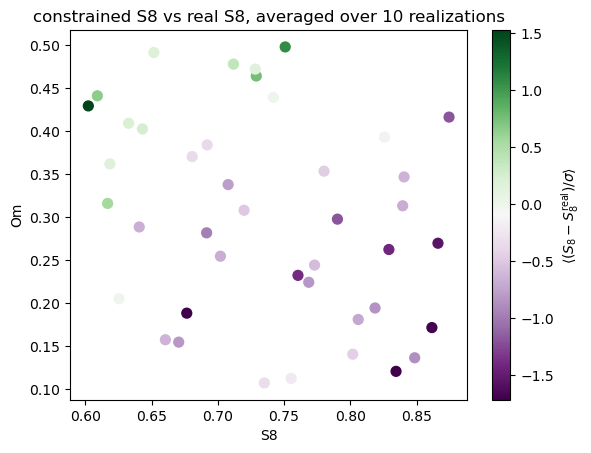

In [7]:
plt.scatter(cosmo_S8[valid], cosmo_Om[valid], c=mean_diff[valid], cmap='PRGn', s=50)
plt.colorbar(label=r'$\langle(S_8 - S_8^{\rm real}) / \sigma\rangle$')
plt.xlabel('S8')
plt.ylabel('Om')
plt.title('constrained S8 vs real S8, averaged over 10 realizations')

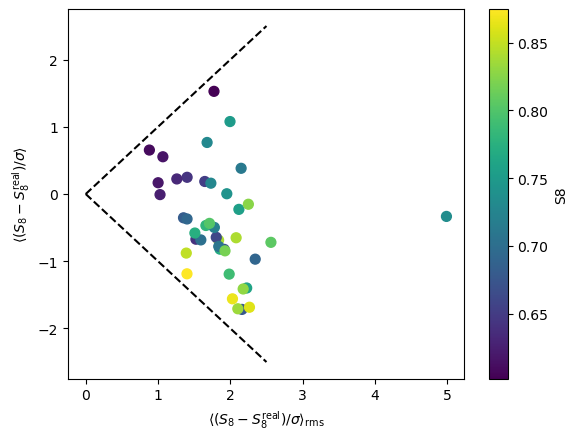

In [8]:
plt.scatter(rms[valid], mean_diff[valid], c=cosmo_S8[valid], cmap='viridis', s=50)
plt.plot([0, 2.5], [0, 2.5], color='k', linestyle='--')
plt.plot([0, 2.5], [0, -2.5], color='k', linestyle='--')
plt.xlabel(r'$\langle(S_8 - S_8^{\rm real}) / \sigma\rangle_{\rm rms}$')
plt.ylabel(r'$\langle (S_8 - S_8^{\rm real}) / \sigma \rangle$')
plt.colorbar(label='S8')